# Spatial Neighborhood Matrices
### Theoretical Foundations and Practical Implementation in R

---

### Foundations: Areal Spatial Data and Spatial Dependence

In spatial data science, **areal (or lattice) data** represent processes aggregated across a discrete partitioning of continuous geographic space into a finite set of $n$ bounded polygonal regions $\{A_1, A_2, \dots, A_n\}$ (such as census tracts, administrative zones, postal codes, or health districts).

Unlike continuous point patterns or geostatistical fields sampled at exact coordinates, areal data present unique modeling challenges:
1. **The Modifiable Areal Unit Problem (MAUP)**: Statistical aggregates depend heavily on the arbitrary administrative boundaries chosen for spatial aggregation.
2. **Spatial Autocorrelation**: In accordance with Tobler's First Law of Geography (*"everything is related to everything else, but near things are more related than distant things"*), observations in geographically proximate regions are rarely independent. Classical statistical frameworks (such as Ordinary Least Squares) that assume independent and identically distributed ($i.i.d.$) errors yield deflated standard errors and inflated type-I error rates when applied to areal data.

To explicitly quantify, test, and model spatial autocorrelation, we must translate the physical configuration of the regions into a formal mathematical structure: the **spatial neighborhood matrix** $\mathbf{W} \in \mathbb{R}^{n \times n}$.

#### Mathematical Formulation of Spatial Neighbors and the Weights Matrix $\mathbf{W}$
Let $\mathcal{N}(i)$ denote the neighborhood set of region $i$, representing all regions $j$ deemed topologically or metric-distancely connected to $i$. By convention, an area cannot be its own neighbor: $i \notin \mathcal{N}(i)$, which enforces zero diagonal entries ($w_{ii} = 0$).

The spatial neighborhood matrix $\mathbf{W}$ encodes these connections into numerical weights:
$$
\mathbf{W} = \begin{pmatrix} 
w_{11} & w_{12} & \cdots & w_{1n} \\
w_{21} & w_{22} & \cdots & w_{2n} \\
\vdots & \vdots & \ddots & \vdots \\
w_{n1} & w_{n2} & \cdots & w_{nn} 
\end{pmatrix}, \quad \text{where } w_{ii} = 0 \text{ for all } i = 1, \dots, n
$$

This notebook demonstrates the primary criteria for constructing $\mathbf{W}$ using the `spdep` package across the 49 planning neighborhoods of **Columbus, Ohio**:
1. **Contiguity Neighbors**: Topological adjacency sharing vertices (Queen) or linear edges (Rook).
2. **$k$-Nearest Neighbors ($k$-NN)**: Fixed degree networks ensuring constant neighborhood cardinality.
3. **Distance-Based Radii ($d$-bands)**: Continuous metric thresholding and establishing the minimum diameter ensuring overall graph connectivity.
4. **Higher-Order Topological Graph Lags**: Multi-step neighborhood rings capturing regional spatial spillover.
5. **Standardization Schemes**: Binary adjacency, row-standardized local averages ($\sum_j w_{ij} = 1$), and continuous inverse-distance gravity decay functions.

---


In [1]:
librarian::shelf(spData, sf, spdep, tidyverse, patchwork)

options(
  ark.plot.width = 10, ark.plot.height = 3.8,
  repr.plot.width = 10, repr.plot.height = 3.8
)


In [2]:
map <- st_read(system.file("shapes/columbus.gpkg", package = "spData"), quiet = TRUE)
st_crs(map) <- NA  # Columbus uses an arbitrary Cartesian coordinate system

coo <- st_centroid(st_geometry(map))
coords <- st_coordinates(coo)


---
## 1. Contiguity-Based Neighbors

#### Conceptual Foundations
Contiguity-based neighborhood structures define connectivity purely through boundary topology rather than coordinate distance. Two regions $A_i$ and $A_j$ are contiguous if their geometric intersection is non-empty: $\partial A_i \cap \partial A_j \neq \emptyset$.

Two primary topological criteria are used, borrowing terminology from the rules of chess:
* **Queen Contiguity** (`queen = TRUE`, default): Areas $A_i$ and $A_j$ are defined as neighbors if their shared boundary contains **at least one single point or vertex**:
  $$\dim(\partial A_i \cap \partial A_j) \ge 0$$
* **Rook Contiguity** (`queen = FALSE`): Areas $A_i$ and $A_j$ are neighbors only if they share a **linear edge segment of positive length**:
  $$\dim(\partial A_i \cap \partial A_j) \ge 1$$
  *(Points touching exclusively at an isolated corner vertex do not constitute Rook neighbors).*

In irregular polygonal administrative data, Queen contiguity is the standard default because complex GIS polygon boundaries frequently exhibit minor digitization artifacts, corner vertices, or irregular junctions where true linear overlap may be missed.

#### Cardinality and Degree Distribution
The number of neighbors associated with area $i$, denoted $|\mathcal{N}(i)|$, is termed its **cardinality** or **vertex degree**. Cardinality typically varies substantially across a spatial lattice:
* **Interior / Urban Tracts**: High density of small, closely packed tracts results in high cardinality ($6$ to $10+$ neighbors).
* **Peripheral / Suburban Tracts**: Large tracts on the exterior boundary of the study domain exhibit fewer neighbors ($1$ to $3$).
* **Boundary Effects**: Edge tracts naturally have fewer recorded neighbors simply because the study domain ends abruptly, not because spatial processes cease at the boundary.


In [3]:
nb <- spdep::poly2nb(map, queen = TRUE)
head(nb)

tibble(cardinality = card(nb)) |>
  count(cardinality, name = "tract_count")


# A tibble: 9 × 2
  cardinality tract_count
        <int>       <int>
1           2           5
2           3           9
3           4          12
4           5           5
5           6           9
6           7           3
7           8           4
8           9           1
9          10           1

In [4]:
lines_queen <- nb2lines(nb, coords = coords, as_sf = TRUE)


In [5]:
p7_2_left <- ggplot() +
  geom_sf(data = map, fill = "#f8fafc", color = "#94a3b8", linewidth = 0.35) +
  geom_sf(data = lines_queen, color = "#2563eb", linewidth = 0.55, alpha = 0.75) +
  geom_sf(data = coo, color = "#1d4ed8", fill = "#ffffff", size = 1.6, shape = 21, stroke = 0.9) +
  labs(title = "Figure 7.2 (Left): Contiguity Neighbors", subtitle = "Queen criteria (shared boundary or point)") +
  theme_void(base_size = 11) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 9),
    plot.margin = margin(2, 4, 2, 4)
  )


In [6]:
id <- 20
map_focal <- map |>
  mutate(
    neighborhood_status = case_when(
      row_number() == id ~ "Area 20",
      row_number() %in% nb[[id]] ~ "Neighbors (8)",
      TRUE ~ "Other Areas"
    ) |>
      fct_relevel("Area 20", "Neighbors (8)", "Other Areas")
  )


In [7]:
p7_2_right <- ggplot(map_focal) +
  geom_sf(aes(fill = neighborhood_status), color = "#94a3b8", linewidth = 0.35) +
  scale_fill_manual(
    values = c("Area 20" = "#0f172a", "Neighbors (8)" = "#38bdf8", "Other Areas" = "#f8fafc"),
    name = ""
  ) +
  labs(title = paste("Figure 7.2 (Right): Neighbors of Area", id), subtitle = "Highlighted contiguous neighbors") +
  theme_void(base_size = 11) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 9),
    plot.margin = margin(2, 4, 2, 4),
    legend.position = "bottom",
    legend.key.size = unit(0.35, "cm")
  )


In [8]:
options(ark.plot.width = 10, ark.plot.height = 3.8, repr.plot.width = 10, repr.plot.height = 3.8)
p7_2_left | p7_2_right


### Notes on Figure 7.2
* **Left Panel (Queen Contiguity Network)**:
  * **Nodes (White circles with blue rims)**: Centroids of the 49 Columbus planning neighborhoods.
  * **Edges (Solid blue lines)**: Connecting pairs of contiguous regions that share at least one boundary point or vertex under Queen contiguity relationships.
  * **Structural Characteristics**: Notice the high density of triangular and tetrahedral cliques in the central-eastern core, representing tightly clustered urban tracts. The western tracts stretch into an elongated peninsula where the degree distribution drops to low connectivity, illustrating how administrative geography directly shapes the topology of the adjacency graph.
* **Right Panel (Focal Neighborhood Analysis: Area 20)**:
  * **Focal Area (Dark Navy, Area 20)**: An urban tract centrally located in the eastern quadrant.
  * **Contiguous Neighbors (Cyan, 8 areas)**: The 8 surrounding tracts satisfying Queen contiguity ($\partial A_{20} \cap \partial A_j \neq \emptyset$).
  * **Analytical Role**: When constructing a spatial autoregressive model or computing local spatial indicators, the spatial lag for Area 20 is derived strictly as a weighted combination of these 8 cyan polygons, while the remaining 40 white polygons receive zero weight.


---
## 2. Metric Neighborhoods: $k$-Nearest Neighbors & Distance Thresholds

When administrative boundaries vary drastically in area or when point coordinates (e.g., centroids or survey sites) are analyzed without boundary polygons, neighborhood relations are constructed using metric Euclidean distance $d_{ij} = \|c_i - c_j\|$ between regional centroids $c_i$ and $c_j$.

#### 2.1 $k$-Nearest Neighbors ($k$-NN)
The $k$-NN criterion assigns each area $i$ exactly $k$ neighbors based on minimal centroid distance:
$$\mathcal{N}_k(i) = \{j \in S \setminus \{i\} : d_{ij} \le d_{(k)}(i)\}$$
where $d_{(k)}(i)$ is the distance from centroid $i$ to its $k$-th closest neighbor.

* **Key Mathematical Properties**:
  * **Constant Degree**: Every area is guaranteed $|\mathcal{N}(i)| = k$ neighbors. This eliminates the risk of isolated units or disconnected components.
  * **Asymmetry**: $k$-NN graphs are generally **directed graphs (asymmetric)**. If area $j$ is among the 3 closest neighbors of a remote area $i$, area $i$ is NOT necessarily among the 3 closest neighbors of $j$ ($j \in \mathcal{N}_k(i) \not\implies i \in \mathcal{N}_k(j)$).
  * **Variable Spatial Scale**: In dense city centers, $k=3$ neighbors spans only a few hundred meters. In expansive peripheral areas, $k=3$ neighbors requires searching across several kilometers.

#### 2.2 Distance-Based Neighbors ($d$-Bands)
The distance-based criterion defines neighbors as all areas whose centroids fall within a specified metric interval $[d_1, d_2]$ (typically $d_1 = 0$):
$$\mathcal{N}_d(i) = \{j \in S \setminus \{i\} : d_1 \le d_{ij} \le d_2\}$$

* **Key Mathematical Properties**:
  * **Symmetry**: Distance-based graphs are strictly **undirected (symmetric)** because Euclidean distance is symmetric ($d_{ij} = d_{ji}$).
  * **Uniform Spatial Scale**: The radius of interaction is physically identical across the entire study domain.
  * **Variable Degree & Risk of Isolates**: Dense areas receive many neighbors, whereas sparse or peripheral areas risk receiving **zero neighbors** if the threshold $d_2$ is chosen too small.

#### 2.3 Resolving Isolated Areas: Deriving the Critical Connectivity Threshold
If an arbitrary, overly restrictive threshold (such as $d_2 = 0.40$) is chosen, several peripheral tracts find no other centroid within that radius, triggering disconnected sub-graphs (`neighbour object has 18 sub-graphs`).

To systematically eliminate isolates without arbitrarily distorting the network, we identify the **minimax distance**, the smallest distance threshold that guarantees **every single area has at least one neighbor**:
1. Compute the nearest neighbor ($k = 1$) for every area: `nb1 <- knn2nb(knearneigh(coo, k = 1))`.
2. Extract the exact Euclidean distance to this closest neighbor: `dist1 <- nbdists(nb1, coo)`.
3. Compute the upper bound: $d_{\min} = \max_{i} \{ \text{dist1}_i \} \approx 0.6188$.

Setting $d_2 = 0.62$ represents the theoretical threshold that prevents empty neighbor sets across all 49 tracts.


In [9]:
nb_k3 <- knn2nb(knearneigh(coo, k = 3))

nb1 <- knn2nb(knearneigh(coo, k = 1))
dist1 <- nbdists(nb1, coo)

dist1 |>
  purrr::flatten_dbl() |>
  summary()

max_d <- 0.62
nb_dist <- dnearneigh(coo, d1 = 0, d2 = max_d)


Warning message:
In knn2nb(knearneigh(coo, k = 1)) : neighbour object has 13 sub-graphs
Warning message:
In dnearneigh(coo, d1 = 0, d2 = max_d) : neighbour object has 2 sub-graphs


In [10]:
lines_k3 <- nb2lines(nb_k3, coords = coords, as_sf = TRUE)
lines_dist <- nb2lines(nb_dist, coords = coords, as_sf = TRUE)


In [11]:
p7_3 <- ggplot() +
  geom_sf(data = map, fill = "#f8fafc", color = "#94a3b8", linewidth = 0.35) +
  geom_sf(data = lines_k3, color = "#059669", linewidth = 0.55, alpha = 0.75) +
  geom_sf(data = coo, color = "#047857", fill = "#ffffff", size = 1.6, shape = 21, stroke = 0.9) +
  labs(title = "Figure 7.3: 3-Nearest Neighbors (k = 3)", subtitle = "Fixed 3 closest neighbors per centroid") +
  theme_void(base_size = 11) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 9),
    plot.margin = margin(2, 4, 2, 4)
  )


In [12]:
p7_4 <- ggplot() +
  geom_sf(data = map, fill = "#f8fafc", color = "#94a3b8", linewidth = 0.35) +
  geom_sf(data = lines_dist, color = "#d97706", linewidth = 0.55, alpha = 0.75) +
  geom_sf(data = coo, color = "#b45309", fill = "#ffffff", size = 1.6, shape = 21, stroke = 0.9) +
  labs(title = bquote("Figure 7.4: Distance-based (" * d <= 0.62 * ")"), subtitle = "Ensures every area has at least one neighbor") +
  theme_void(base_size = 11) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 9),
    plot.margin = margin(2, 4, 2, 4)
  )


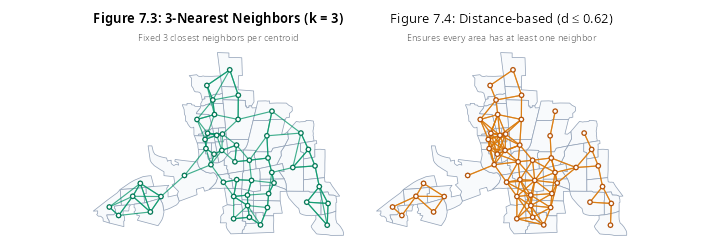

In [13]:
options(ark.plot.width = 10, ark.plot.height = 3.5, repr.plot.width = 10, repr.plot.height = 3.5)
p7_3 | p7_4


### Notes on Figures 7.3 & 7.4
* **Figure 7.3 ($k = 3$ Nearest Neighbors)**:
  * **Uniform Node Degree**: Every centroid has exactly 3 departing edges.
  * **Spatial Footprint Variation**: In the urban cluster (northeast and center), edges are short and compact. In the western panhandle, edges stretch extensively eastward across the city to satisfy the requirement of $k = 3$, demonstrating how $k$-NN adapts neighborhood radius to geographic density.
* **Figure 7.4 (Distance-Based Radius, $d \le 0.62$)**:
  * **Variable Node Degree**: Dense central areas are interconnected by dense bundles of edges (areas having 8-12 neighbors), while peripheral tracts in the south and west connect via only 1 or 2 long-range links.
  * **Universal Connectivity**: Because $d = 0.62$ was derived as the maximum 1-NN distance, no node in the graph is disconnected ($|\mathcal{N}(i)| \ge 1$ for all $i = 1, \dots, 49$).


---
## 3. Higher-Order Topological Spatial Lags

#### Topological Graph Distance and Spatial Decay
Spatial interaction often extends beyond immediately adjacent polygons. Spatial spillover, diffusion, environmental transmission, and economic externalities dissipate across successive geographic tiers.

Topological distance on a contiguity graph measures the shortest path length (minimum number of boundary crossings) between two areas:
* **Order 1 (Lag 1)**: Immediate physical neighbors:
  $$\mathcal{N}^{(1)}(i) = \{j : \partial A_i \cap \partial A_j \neq \emptyset\}$$
* **Order 2 (Lag 2)**: Neighbors of neighbors, **excluding self ($i$) and first-order neighbors ($\mathcal{N}^{(1)}(i)$)**:
  $$\mathcal{N}^{(2)}(i) = \{k \in \mathcal{N}^{(1)}(j) \text{ for some } j \in \mathcal{N}^{(1)}(i) \mid k \neq i, k \notin \mathcal{N}^{(1)}(i)\}$$
  Lag 2 captures the second concentric spatial ring surrounding an area.
* **Cumulative Lags (Order 1 through $k$)**:
  $$\mathcal{N}^{(\le k)}(i) = \bigcup_{m=1}^k \mathcal{N}^{(m)}(i)$$
  Cumulating lags combines the direct and indirect tiers into an expanding regional catchment zone.

In `spdep`, `nblag(neighbours = nb, maxlag = 2)` computes a list of disjoint neighbor objects for each lag order, while `nblag_cumul()` aggregates them across all orders up to `maxlag`.


In [14]:
nblags <- spdep::nblag(neighbours = nb, maxlag = 2)

nblagsc <- spdep::nblag_cumul(nblags)


In [15]:
lines_l1 <- nb2lines(nblags[[1]], coords = coords, as_sf = TRUE)
lines_l2 <- nb2lines(nblags[[2]], coords = coords, as_sf = TRUE)
lines_lc <- nb2lines(nblagsc, coords = coords, as_sf = TRUE)


In [16]:
p7_6_1 <- ggplot() +
  geom_sf(data = map, fill = "#f8fafc", color = "#cbd5e1", linewidth = 0.3) +
  geom_sf(data = lines_l1, color = "#0284c7", linewidth = 0.5, alpha = 0.7) +
  geom_sf(data = coo, color = "#0369a1", fill = "#ffffff", size = 1.4, shape = 21, stroke = 0.8) +
  labs(title = "First Order (Lag 1)", subtitle = "Direct boundary touches") +
  theme_void(base_size = 10) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8.5),
    plot.margin = margin(2, 2, 2, 2)
  )


In [17]:
p7_6_2 <- ggplot() +
  geom_sf(data = map, fill = "#f8fafc", color = "#cbd5e1", linewidth = 0.3) +
  geom_sf(data = lines_l2, color = "#7c3aed", linewidth = 0.5, alpha = 0.7) +
  geom_sf(data = coo, color = "#6d28d9", fill = "#ffffff", size = 1.4, shape = 21, stroke = 0.8) +
  labs(title = "Second Order (Lag 2)", subtitle = "Neighbors of neighbors") +
  theme_void(base_size = 10) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8.5),
    plot.margin = margin(2, 2, 2, 2)
  )


In [18]:
p7_6_c <- ggplot() +
  geom_sf(data = map, fill = "#f8fafc", color = "#cbd5e1", linewidth = 0.3) +
  geom_sf(data = lines_lc, color = "#ea580c", linewidth = 0.5, alpha = 0.6) +
  geom_sf(data = coo, color = "#c2410c", fill = "#ffffff", size = 1.4, shape = 21, stroke = 0.8) +
  labs(title = "Order 1 until Order 2", subtitle = "Cumulative interaction zone") +
  theme_void(base_size = 10) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8.5),
    plot.margin = margin(2, 2, 2, 2)
  )


In [19]:
options(ark.plot.width = 11.5, ark.plot.height = 3.2, repr.plot.width = 11.5, repr.plot.height = 3.2)
(p7_6_1 | p7_6_2 | p7_6_c) +
  plot_annotation(
    title = "Figure 7.6: Contiguity Neighbors by Lag Order",
    theme = theme(plot.title = element_text(face = "bold", hjust = 0.5, size = 13))
  )


### Notes on Figure 7.6
* **First Order (Lag 1, Blue)**:
  Represents immediate boundary-sharing contiguity. Network edges connect strictly adjacent centroids without crossing intermediate polygons.
* **Second Order (Lag 2, Purple)**:
  The purple edges **leap over intermediate tracts**, connecting centroids that are separated by exactly two boundary transitions. This ring models secondary spatial diffusion effects (e.g., regional commute patterns or secondary wave spreading).
* **Order 1 through 2 (Cumulative, Orange)**:
  Combines both tiers into a dense regional network where each centroid connects to both its immediate perimeter and its secondary buffer zone, significantly increasing connectivity across the metropolitan area.


---
## 4. Spatial Weights Matrices ($\mathbf{W}$)

#### Mathematical Formalization of Weights
A neighbor list ($\text{class } nb$) specifies only the binary topological existence of a connection. To perform spatial autoregression, calculate spatial lags, or compute Moran's $I$, the adjacency graph must be converted into a numerical matrix $\mathbf{W} \in \mathbb{R}^{n \times n}$.

The function `spdep::nb2listw()` generates spatial weights objects according to specific analytical requirements:

#### 4.1 Row-Standardization (`style = "W"`)
The most widely used formulation in spatial statistics normalizes each row of the binary adjacency matrix by its row sum:
$$
w^*_{ij} = \frac{w_{ij}}{\sum_{k=1}^n w_{ik}} = \begin{cases} 
\frac{1}{n_i} & \text{if } j \in \mathcal{N}(i) \\
0 & \text{otherwise}
\end{cases}
$$
where $n_i = |\mathcal{N}(i)|$ is the number of neighbors for area $i$.

* **Key Mathematical Properties**:
  * **Row Sum Invariance**: Every row sums exactly to 1: $\sum_{j=1}^n w^*_{ij} = 1$.
  * **Spatial Lag Interpretation**: For an observed attribute vector $\mathbf{y} = (y_1, \dots, y_n)^T$, the matrix product $\mathbf{W}\mathbf{y}$ computes the **local spatial average** of the variable across neighboring areas:
    $$[\mathbf{W}\mathbf{y}]_i = \sum_{j \in \mathcal{N}(i)} \frac{1}{n_i} y_j$$
  * **Asymmetry**: Even when the underlying contiguity graph is strictly symmetric ($w_{ij} = w_{ji}$), the row-standardized matrix $\mathbf{W}$ is **asymmetric** whenever neighbor cardinalities differ ($n_i \neq n_j \implies w^*_{ij} \neq w^*_{ji}$).
  * **Spectral Property**: The maximum eigenvalue of $\mathbf{W}$ is strictly bounded at $\lambda_{\max} = 1$, ensuring stability in spatial autoregressive (SAR/CAR) parameter estimation.

#### 4.2 Inverse Distance Weights (`style = "B"` with $1/d_{ij}$)
When continuous physical distance within contiguous boundaries governs interaction, weights are formulated using an inverse distance gravity decay:
$$
w_{ij} = \begin{cases} 
\frac{1}{d_{ij}^\alpha} & \text{if } j \in \mathcal{N}(i) \\
0 & \text{otherwise}
\end{cases}
$$
where $d_{ij}$ is the Euclidean distance between centroids and $\alpha \ge 1$ is a distance decay exponent (typically $\alpha = 1$). This combines topological boundary constraints with continuous metric proximity.

#### 4.3 Sparse Storage Representation (`listw`)
In practical spatial data science, spatial weight matrices for large regions ($n > 10^4$) are extremely sparse (typically $<0.1\%$ non-zero entries). `spdep` uses the `listw` class (storing neighbor IDs and non-zero weight vectors in memory-efficient lists) rather than dense $n \times n$ matrices, avoiding memory bottlenecks.


In [20]:
nbw_std <- spdep::nb2listw(nb, style = "W")
cat("Row-standardized weights (areas 1 to 3):\n")
print(nbw_std$weights[1:3])

dists <- spdep::nbdists(nb, coo)
ids <- dists |> purrr::map(\(x) 1 / x)
nbw_inv <- spdep::nb2listw(nb, glist = ids, style = "B")
cat("\nInverse distance weights (areas 1 to 3):\n")
print(nbw_inv$weights[1:3])


Row-standardized weights (areas 1 to 3):
[[1]]
[1] 0.5 0.5

[[2]]
[1] 0.3333333 0.3333333 0.3333333

[[3]]
[1] 0.25 0.25 0.25 0.25




Inverse distance weights (areas 1 to 3):
[[1]]
[1] 1.670235 1.725073

[[2]]
[1] 1.670235 1.404736 2.943309

[[3]]
[1] 1.725073 1.404736 1.782670 1.910694



In [21]:
tidy_matrix <- function(mat) {
  as.data.frame(mat) |>
    as_tibble(rownames = "i") |>
    pivot_longer(cols = -i, names_to = "j", values_to = "weight") |>
    mutate(
      i = as.numeric(i),
      j = as.numeric(gsub("V", "", j))
    )
}

df_m1 <- tidy_matrix(spdep::listw2mat(nbw_std))
df_m2 <- tidy_matrix(spdep::listw2mat(nbw_inv))


In [22]:
p7_8_left <- ggplot(df_m1, aes(x = j, y = i, fill = weight)) +
  geom_tile(color = "white", linewidth = 0.05) +
  scale_fill_viridis_c(option = "mako", direction = -1, name = "Weight") +
  scale_y_reverse(breaks = c(10, 20, 30, 40), expand = c(0, 0)) +
  scale_x_continuous(breaks = c(10, 20, 30, 40), position = "top", expand = c(0, 0)) +
  coord_fixed() +
  labs(
    title = "Row-Standardized Weights (style = 'W')",
    subtitle = "Binary contiguity (each row sums to 1)",
    x = "Neighbor Area j",
    y = "Focal Area i"
  ) +
  theme_minimal(base_size = 10) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8.5),
    panel.grid = element_blank(),
    plot.margin = margin(2, 4, 2, 4)
  )


In [23]:
p7_8_right <- ggplot(df_m2, aes(x = j, y = i, fill = weight)) +
  geom_tile(color = "white", linewidth = 0.05) +
  scale_fill_viridis_c(option = "viridis", direction = -1, name = "Weight") +
  scale_y_reverse(breaks = c(10, 20, 30, 40), expand = c(0, 0)) +
  scale_x_continuous(breaks = c(10, 20, 30, 40), position = "top", expand = c(0, 0)) +
  coord_fixed() +
  labs(
    title = "Inverse Distance Weights (style = 'B')",
    subtitle = "Weights inversely proportional to distance (1 / d_ij)",
    x = "Neighbor Area j",
    y = "Focal Area i"
  ) +
  theme_minimal(base_size = 10) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8.5),
    panel.grid = element_blank(),
    plot.margin = margin(2, 4, 2, 4)
  )


In [24]:
options(ark.plot.width = 9.5, ark.plot.height = 4.8, repr.plot.width = 9.5, repr.plot.height = 4.8)
(p7_8_left | p7_8_right) +
  plot_annotation(
    title = "Figure 7.8: Spatial Weights Matrices Comparison (W)",
    theme = theme(plot.title = element_text(face = "bold", hjust = 0.5, size = 13))
  )


### Notes on Figure 7.8
* **Axes Interpretation**: The vertical axis index ($i$) denotes the focal area; the horizontal axis index ($j$) denotes the potential neighbor area.
* **Zero Diagonal ($w_{ii} = 0$)**: The clear diagonal line through the matrix represents the convention of zero self-weight ($w_{ii} = 0$).
* **Sparsity Pattern (White Background)**: Over $85\%$ of the matrix entries are blank, reflecting the localized nature of spatial processes.
* **Row-Standardized Heatmap (Left)**:
  Tile intensity represents $w^*_{ij} = 1/n_i$. Focal tracts with many neighbors appear as lighter cells ($1/8 = 0.125$), while focal tracts with few neighbors show higher individual weights ($1/2 = 0.50$). This guarantees each row sums to unity.
* **Inverse-Distance Heatmap (Right)**:
  Tile intensity corresponds to $1/d_{ij}$. Centroid pairs that are geographically close exhibit high weights (bright yellow/green highlights), providing continuous metric differentiation among adjacent polygons.
